# California Housing Price Prediction

## 1. Project Overview

The objective of this project is to build a Machine Learning model that predicts the **median house value of California districts** from demographic and geographic features.

The workflow is:

1. Exploratory Data Analysis (EDA), including data-quality checks
2. A **fair experimental design**: one fixed train/test split shared by every model
3. Linear Regression baselines under different data-preparation strategies
4. Feature engineering
5. Model comparison with 5-fold cross-validation
6. Final evaluation and model interpretation

**Central question:** the target variable is right-censored (prices above $\$500,000$ are capped). Does removing those rows really improve the model, or are other data-quality issues (extreme outliers in the features) responsible for the poor baseline performance?

## 2. Business Problem

Accurately estimating housing prices is valuable for real estate agencies, property investors, financial institutions and home buyers. The goal is to estimate the median house value of a district using demographic and geographic variables.

## 3. Dataset

California Housing dataset (scikit-learn): **20,640 districts** and **8 predictors** describing demographic and housing characteristics of California district.

The target `Price` is the median house value expressed in **units of \$100,000** (so `Price = 2.5` means $\$250,000$).

| Attribute | Description |
|-----------|-------------|
| MedInc | median income in block group (in $10,000) |
| HouseAge | median house age in block group |
| AveRooms | average number of rooms per household |
| AveBedrms | average number of bedrooms per household |
| Population | block group population |
| AveOccup | average number of household members |
| Latitude | block group latitude |
| Longitude | block group Longitude |

## 4. Setup and Data Loading

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

%matplotlib inline
sns.set_theme(style="whitegrid")

SEED = 42
CAP = 5.0  # prices >= 5.0 ($500,000) are censored in this dataset
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMAGES / name, dpi=300, bbox_inches="tight")

In [33]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.rename(columns={"MedHouseVal": "Price"})
FEATURES = list(housing.feature_names)

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 5. Exploratory Data Analysis (EDA)

### 5.1 General structure

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [35]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
Price,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


### 5.2 Correlation analysis

The heatmap shows the linear relationship between variables. `MedInc` is expected to be the strongest linear predictor of `Price`.

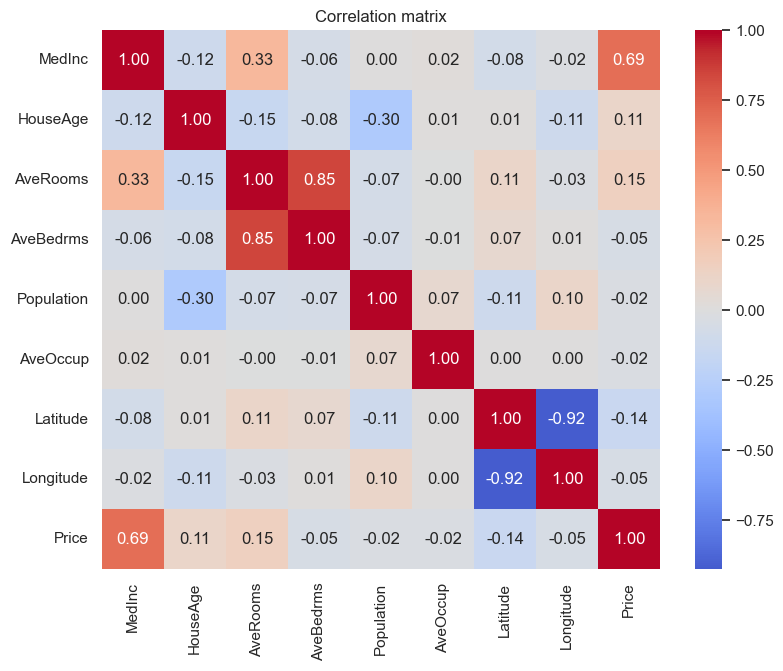

In [36]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save_fig("correlation_heatmap.png")
plt.show()

### 5.3 Target distribution and right-censoring

House values above $\$500,000$ are recorded at the cap value, creating an artificial spike at the right edge of the distribution.

Censored districts: 992 (4.81% of the data)


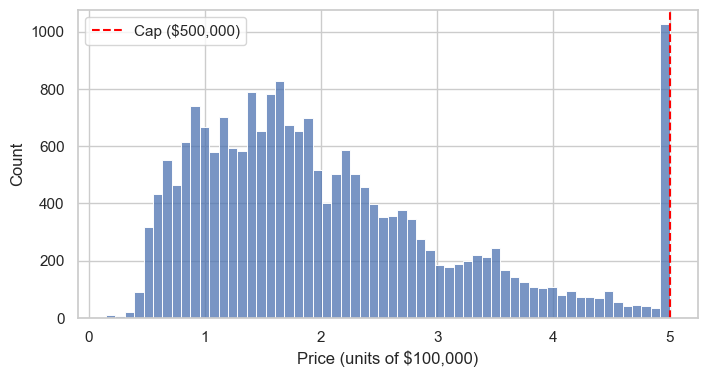

In [37]:
censored = df["Price"] >= CAP
print(f"Censored districts: {censored.sum()} ({censored.mean():.2%} of the data)")

plt.figure(figsize=(8, 4))
sns.histplot(df["Price"], bins=60)
plt.axvline(CAP, color="red", linestyle="--", label="Cap ($500,000)")
plt.xlabel("Price (units of $100,000)")
plt.legend()
save_fig("original_price.png")
plt.show()

### 5.4 Geographic view

Location is a major price driver in real estate. Coastal areas around San Francisco and Los Angeles stand out.

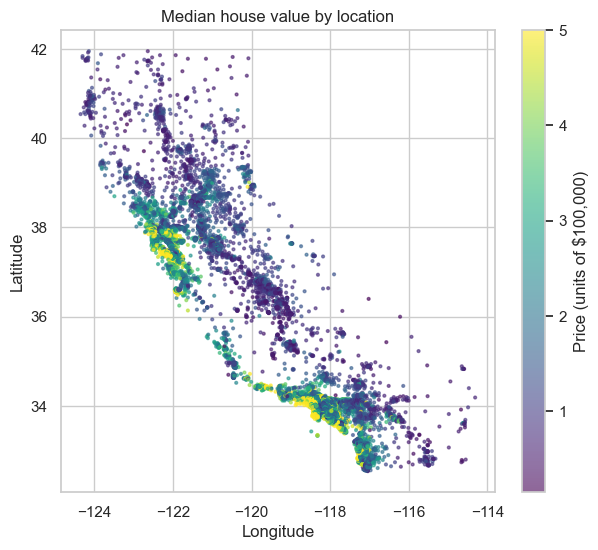

In [38]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["Price"], s=4, cmap="viridis", alpha=0.6)
plt.colorbar(sc, label="Price (units of $100,000)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Median house value by location")
save_fig("price_map.png")
plt.show()

### 5.5 Outliers in the predictors

The census-derived averages (**AveRooms**, **AveBedrms**, **AveOccup**) are ratios computed for each district, so districts with very few households can produce **absurd values** (for example, hundreds of people per household). Extreme values like these can dominate the squared error of a linear model, so they are checked here before drawing any conclusion about the censoring.

,count,mean,std,min,1%,50%,99%,max
AveRooms,20640.0,5.43,2.47,0.85,2.58,5.23,10.36,141.91
AveBedrms,20640.0,1.10,0.47,0.33,0.87,1.05,2.13,34.07
AveOccup,20640.0,3.07,10.39,0.69,1.54,2.82,5.39,1243.33
Population,20640.0,1425.48,1132.46,3.00,88.00,1166.00,5805.83,35682.00


Districts with AveOccup > 10: 37 (0.18%)
Share of those that are also price-capped: 10.8%


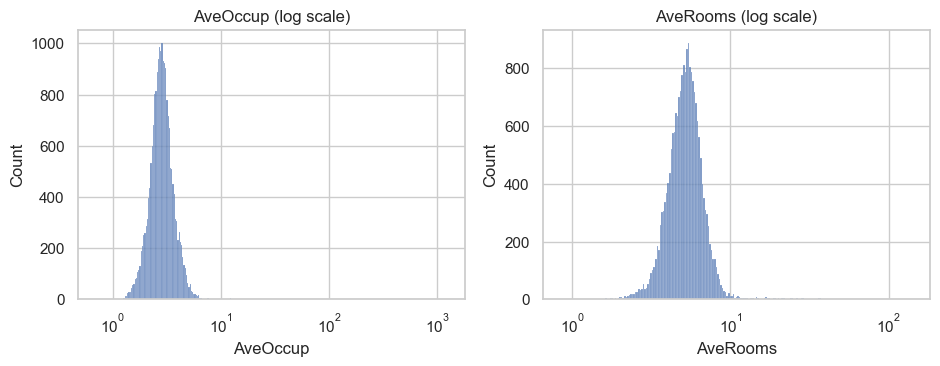

In [39]:
cols = ["AveRooms", "AveBedrms", "AveOccup", "Population"]
display(df[cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2))

extreme = df["AveOccup"] > 10
print(f"Districts with AveOccup > 10: {extreme.sum()} ({extreme.mean():.2%})")
print(f"Share of those that are also price-capped: {(df.loc[extreme, 'Price'] >= CAP).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["AveOccup"], log_scale=True, ax=axes[0]); axes[0].set_title("AveOccup (log scale)")
sns.histplot(df["AveRooms"], log_scale=True, ax=axes[1]); axes[1].set_title("AveRooms (log scale)")
save_fig("feature_outliers.png")
plt.show()

## 6. Experimental Design

To make every comparison **fair**:

- One train/test split (80/20, fixed seed) is created **once** and reused by all models.
- Every model is evaluated on the **same full test set**, including censored observations, because those are real districts the model will face in practice.
- Any cleaning or clipping is learned **from the training set only**, so no information leaks from the test set.
- Besides RMSE, MAE and R², the RMSE on the *uncensored* part of the test set is also reported, as a reference.

> In the first version of this project, the cleaned model was evaluated on a test set without the expensive houses. That test set is easier to predict, so the improvement could not be attributed to the cleaning itself.

In [40]:
X = df[FEATURES]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

y_test_arr = y_test.to_numpy()
unc = y_test_arr < CAP          # uncensored mask for the test set

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

results = []

def evaluate(name, model, X_tr, y_tr, X_te):
    """Fit on the given training data, evaluate on the shared test set."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    results.append({
        "Model": name,
        "RMSE": rmse(y_test_arr, pred),
        "MAE": mean_absolute_error(y_test_arr, pred),
        "R2": r2_score(y_test_arr, pred),
        "RMSE (uncensored test)": rmse(y_test_arr[unc], pred[unc]),
    })
    return model, pred

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows "
      f"({(~unc).sum()} censored in test)")

Train: 16512 rows | Test: 4128 rows (184 censored in test)


## 7. Linear Regression Experiments

Four strategies are compared with the same algorithm:

| Experiment | Training data | Feature outliers |
|-----------|---------------|------------------|
| A. Baseline | all rows | untouched |
| B. Drop censored | rows with `Price < 5` | untouched |
| C. Clip outliers | all rows | capped at the 99th percentile of the training set |
| D. Both | rows with `Price < 5` | capped at the 99th percentile of the training set |


A small custom transformer learns the clipping limits from the training data only.



In [41]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Caps the given columns at an upper quantile learned during fit()."""

    def __init__(self, columns=None, upper=0.99):
        self.columns = columns
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        cols = [c for c in self.columns if c in X.columns]
        self.upper_ = {c: X[c].quantile(self.upper) for c in cols}
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c, limit in self.upper_.items():
            X[c] = X[c].clip(upper=limit)
        return X

CLIP_COLS = ["AveRooms", "AveBedrms", "AveOccup", "Population", "RoomsPerPerson", "BedroomRatio"]

In [42]:
not_cens_train = (y_train < CAP).to_numpy()

# A. Baseline
lm_A, pred_A = evaluate("A. Baseline (all data)",
                        LinearRegression(),
                        X_train,
                        y_train,
                        X_test)

# B. Drop censored rows from the training set only
lm_B, pred_B = evaluate("B. Drop censored (train only)",
                        LinearRegression(),
                        X_train[not_cens_train],
                        y_train[not_cens_train],
                        X_test)

# C. Clip feature outliers, keep every row (incluiding censored rows)
lm_C, pred_C = evaluate("C. Clip feature outliers",
                        make_pipeline(QuantileClipper(CLIP_COLS), LinearRegression()),
                        X_train,
                        y_train,
                        X_test)

# D. Clips feauture outliers and drops censored rows
lm_D, pred_D = evaluate("D. Drop censored + clip",
                        make_pipeline(QuantileClipper(CLIP_COLS), LinearRegression()),
                        X_train[not_cens_train],
                        y_train[not_cens_train],
                        X_test)

res = pd.DataFrame(results).set_index("Model")
res["MAE ($)"] = (res["MAE"] * 100_000).round(0)
res.round(4)

,RMSE,MAE,R2,RMSE (uncensored test),MAE ($)
Model,,,,,
A. Baseline (all data),0.7456,0.5332,0.5758,0.6578,53320.0
B. Drop censored (train only),0.7444,0.5246,0.5772,0.6486,52465.0
C. Clip feature outliers,0.6794,0.4978,0.6477,0.5996,49785.0
D. Drop censored + clip,0.6844,0.4907,0.6425,0.5952,49074.0


In [43]:
baseline = "A. Baseline (all data)"
metrics = ["RMSE", "MAE", "R2", "RMSE (uncensored test)"]

base = res.loc[baseline, metrics]
abs_change = res[metrics].sub(base, axis=1)
pct_change = abs_change.div(base, axis=1) * 100

print("Percentage change vs baseline (%)")
display(pct_change.drop(index=baseline).round(2))

Percentage change vs baseline (%)


,RMSE,MAE,R2,RMSE (uncensored test)
Model,,,,
B. Drop censored (train only),-0.16,-1.60,0.24,-1.40
C. Clip feature outliers,-8.87,-6.63,12.49,-8.85
D. Drop censored + clip,-8.21,-7.96,11.59,-9.53


Considering the unchanged data model as the baseline, the experiment B doesn´t shows a remarcable improvement after removing censored values, reducing RMSE only for $0.16%$ and icreases the explained variance (R-squared) only for $0.24%$. On the other hand, the experiment C reduces RMSE almost on $9%$ and increases the explained variance on $12.5%$. Then we can say the poor baseline was mostly caused by **extreme outliers in the features**, not by the censored target.


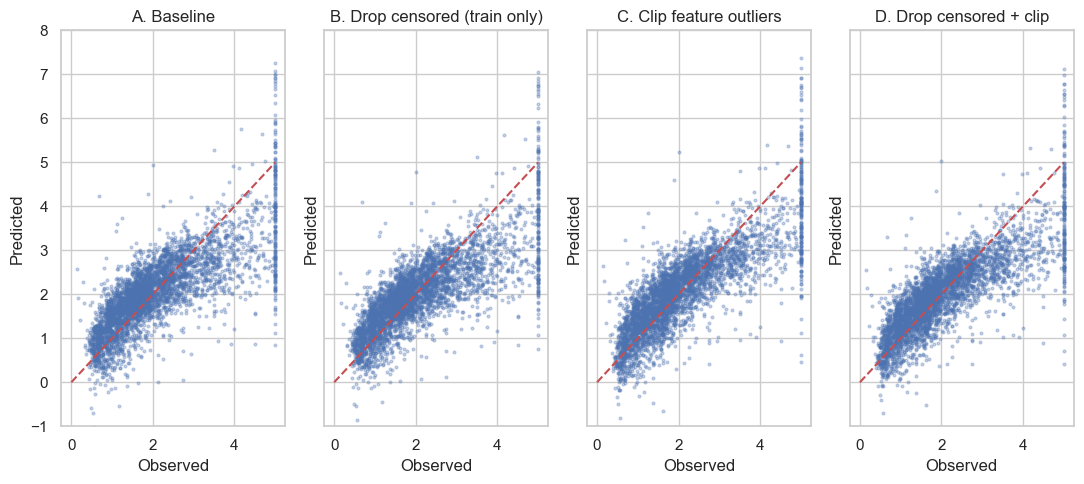

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(11, 5), sharex=True, sharey=True)
for ax, pred, title in zip(axes, [pred_A, pred_B, pred_C, pred_D], ["A. Baseline", "B. Drop censored (train only)", "C. Clip feature outliers","D. Drop censored + clip"]):
    ax.scatter(y_test_arr, pred, s=4, alpha=0.3)
    ax.plot([0, 5], [0, 5], "r--")
    ax.set_title(title); ax.set_xlabel("Observed"); ax.set_ylabel("Predicted")
    ax.set_ylim(-1, 8)
plt.tight_layout()
save_fig("actual_vs_predicted_linear.png")
plt.show()

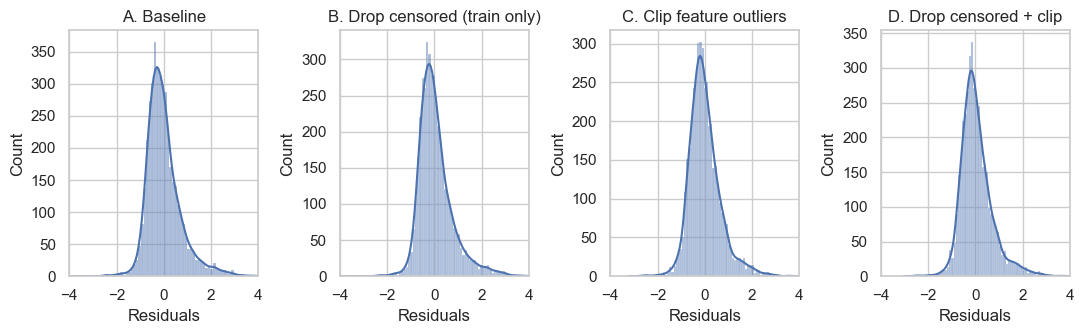

In [45]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.5), sharex=True)
for ax, pred, title in zip(axes, [pred_A, pred_B, pred_C, pred_D], ["A. Baseline",  "B. Drop censored (train only)", "C. Clip feature outliers", "D. Drop censored + clip"]):
    sns.histplot(y_test_arr - pred, kde=True, ax=ax)
    ax.set_title(title); ax.set_xlabel("Residuals")
    ax.set_xlim(-4, 4)
plt.tight_layout()
save_fig("residuals_linear.png")
plt.show()

### 7.1 Coefficients for Linear Models

Since clipping does not rescale the variables, coefficients are directly comparable across experiments.

In [46]:
coefs = pd.DataFrame({
    "A. Baseline": lm_A.coef_,
    "B. Drop censored": lm_B.coef_,
    "C. Clip outliers": lm_C[-1].coef_, # [-1] = the LinearRegression step
    "D. Drop censored + clip": lm_D[-1].coef_,
}, index=FEATURES)

coefs.loc["Intercept"] = [lm_A.intercept_, lm_B.intercept_,
                          lm_C[-1].intercept_, lm_D[-1].intercept_]
display(coefs.round(6))

,A. Baseline,B. Drop censored,C. Clip outliers,D. Drop censored + clip
MedInc,0.448675,0.441305,0.433074,0.431244
HouseAge,0.009724,0.008245,0.011474,0.010003
AveRooms,-0.123323,-0.120844,-0.107098,-0.113888
AveBedrms,0.783145,0.717909,0.977773,0.888208
Population,-0.000002,0.000008,0.000052,0.000055
AveOccup,-0.003526,-0.003223,-0.363863,-0.302021
Latitude,-0.419792,-0.376758,-0.429156,-0.386807
Longitude,-0.433708,-0.392968,-0.421291,-0.384399
Intercept,-37.023278,-33.629341,-34.513498,-31.667877


The most notable change across the experiments is in the coefficient of **AveOccup**, which goes from $−0.003$ in the baseline to between $−0.30$ and $−0.36$ after clipping outliers (C and D), roughly 100 times larger. When extreme values are kept, districts with very high occupancy likely distort the fit and flatten the slope. This is consistent with the large reduction in RMSE observed in section 7.

The remaining coefficients are comparatively stable across experiments. **MedInc** stays between $0.43$ and $0.45$, and AveRooms and AveBedrms keep opposite signs in all four experiments (about $−0.11$ to $−0.12$ and $+0.72$ to $+0.98$, respectively). **Latitude** and **Longitude** have almost identical coefficients within each experiment, and the gap between them narrows after clipping. Population is close to zero in all experiments, but this is mainly due to its scale (number of people), so its coefficient is not directly interpretable here.

### 7.2 Collinearity check (VIF)

The variance inflation factor (VIF) measures how well each feature can be predicted from the other features. Values above 5 indicate notable collinearity, which makes individual coefficients harder to interpret.

In [47]:
def vif_table(X):
    out = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        out[col] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False).round(1)

vif_table(X_train)

Latitude      9.2
Longitude     8.9
AveRooms      7.9
AveBedrms     6.6
MedInc        2.5
HouseAge      1.2
Population    1.1
AveOccup      1.0
dtype: float64

The variance inflation factors (VIF) show notable collinearity in two groups of variables: **Latitude** and **Longitude** (VIF ≈ 9) and **AveRooms** and **AveBedrms** (VIF ≈ 7-8). This is consistent with the opposite signs and large magnitudes seen in the coefficients of **AveRooms** and **AveBedrms**, so the individual coefficients of these variables should not be interpreted separately. It does not affect the predictive performance of the tree-based models.

### 7.3 Experiment Comparisson
Using the baseline (A) as the starting point, dropping the censored rows from the training set (B) has no noticeable impact on performance. In contrast, clipping the feature outliers (C) reduces the error considerably (RMSE −8.9%) and raises the explained variance (R² from 0.576 to 0.648). Combining both strategies (D) performs about the same as C alone, with C slightly better in RMSE and R². Even so, the best linear model leaves more than a third of the variance unexplained, which suggests that the relationship between the features and the price is not purely linear. For this reason, non-linear supervised models are tested in the following sections.



## 8. Feature Engineering

New variables built **only from the same row** (no information from other rows, so there is no leakage):

- `BedroomRatio`: share of rooms that are bedrooms
- `RoomsPerPerson`: living space per resident
- `DistNearestCity`: distance in km to the nearest of five major California cities (Los Angeles, San Francisco, San Diego, San Jose, Sacramento). This captures the price premium of urban areas better than raw **Latitude**/**Longitude**.

Note: The distance was obtained through **Haversine distance**

$$
a = \sin^2\left(\frac{\varphi_2 - \varphi_1}{2}\right) + \cos(\varphi_1)\,\cos(\varphi_2)\,\sin^2\left(\frac{\lambda_2 - \lambda_1}{2}\right)
$$

$$
d = 2R \cdot \arcsin\left(\sqrt{a}\right)
$$

where:

- $\varphi_1, \varphi_2$: latitudes of the two points (in radians)
- $\lambda_1, \lambda_2$: longitudes of the two points (in radians)
- $R = 6371$ km: mean radius of the Earth
- $d$: distance between the points along the surface of the sphere (in km)

In [48]:
CITIES = {
    "Los Angeles": (34.05, -118.24),
    "San Francisco": (37.77, -122.42),
    "San Diego": (32.72, -117.16),
    "San Jose": (37.34, -121.89),
    "Sacramento": (38.58, -121.49),
}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def add_features(data):
    data = data.copy()
    data["BedroomRatio"] = data["AveBedrms"] / data["AveRooms"]
    data["RoomsPerPerson"] = data["AveRooms"] / data["AveOccup"]
    dists = np.column_stack([
        haversine_km(data["Latitude"], data["Longitude"], lat, lon)
        for lat, lon in CITIES.values()
    ])
    data["DistNearestCity"] = dists.min(axis=1)
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,BedroomRatio,RoomsPerPerson,DistNearestCity
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,0.200576,1.359130,12.213004
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,0.232703,2.573820,31.997881
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,0.174486,2.073224,216.519120
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,0.258269,1.002116,5.745833
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,0.180940,2.725400,195.623617


## 9. Model Comparison with Cross-Validation

Instead of trusting a single split, each model is evaluated with **5-fold cross-validation on the training set**. The test set stays untouched until the final evaluation.

Models compared, each on the base features and on the engineered features:

- Linear Regression and Ridge (with clipping and scaling)
- Random Forest
- Histogram Gradient Boosting

Cross-validation uses all training rows (censored included), since the tree-based models handle a capped target without trouble.

In [49]:
def make_models():
    return {
        "Linear Regression": make_pipeline(QuantileClipper(CLIP_COLS), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(QuantileClipper(CLIP_COLS), StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=2,                                          n_jobs=-1, random_state=SEED),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
    }

feature_sets = {
    "Base": (X_train, X_test),
    "Engineered": (X_train_fe, X_test_fe),
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []

for fs_name, (Xtr, _) in feature_sets.items():
    for model_name, model in make_models().items():
        cv = cross_validate(model, Xtr, y_train, cv=kf,
                            scoring=("neg_root_mean_squared_error", "r2"))
        rmse_cv = -cv["test_neg_root_mean_squared_error"]
        cv_rows.append({
            "Features": fs_name,
            "Model": model_name,
            "CV RMSE (mean)": rmse_cv.mean(),
            "CV RMSE (std)": rmse_cv.std(),
            "CV R2 (mean)": cv["test_r2"].mean(),
        })



cv_df = pd.DataFrame(cv_rows).sort_values("CV RMSE (mean)").reset_index(drop=True)
cv_df.round(4)

,Features,Model,CV RMSE (mean),CV RMSE (std),CV R2 (mean)
0,Engineered,Hist Gradient Boosting,0.4619,0.0106,0.8403
1,Base,Hist Gradient Boosting,0.4722,0.0115,0.8331
2,Engineered,Random Forest,0.4910,0.0125,0.8196
3,Base,Random Forest,0.5100,0.0120,0.8053
4,Engineered,Ridge,0.6487,0.0152,0.6851
5,Engineered,Linear Regression,0.6487,0.0152,0.6851
6,Base,Linear Regression,0.6689,0.0146,0.6652
7,Base,Ridge,0.6689,0.0146,0.6652


**Hist Gradient Boosting with the engineered features** achieves the lowest cross-validated RMSE ($0.4619$) and the highest R² ($0.8403$), so it is the best configuration.

The engineered features improved every model, although the gain is modest compared to the fold-to-fold variability (RMSE gains of roughly $0.01$ to $0.02$, with standard deviations around $0.01$ to $0.015$).

The largest improvement comes from the choice of algorithm: moving from a linear model to Hist Gradient Boosting reduces the RMSE by about $29%$. Ridge and Linear Regression give identical results, since the regularization (alpha = 1) is negligible with this amount of data.

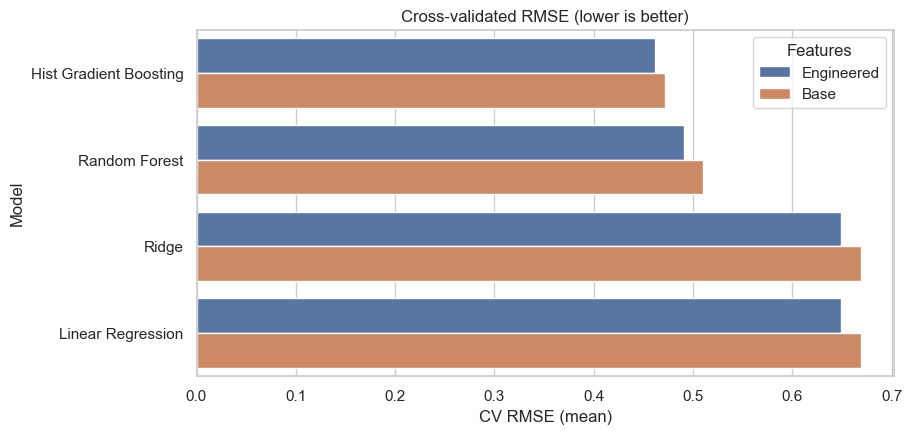

In [50]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=cv_df, y="Model", x="CV RMSE (mean)", hue="Features")
plt.title("Cross-validated RMSE (lower is better)")
save_fig("cv_comparison.png")
plt.show()

## 10. Final Evaluation on the Test Set

The best configuration according to cross-validation is refit on the full training set and evaluated **once** on the test set.

In [51]:
best = cv_df.iloc[0]
print(f"Best configuration: {best['Model']} with {best['Features']} features")

Xtr_best, Xte_best = feature_sets[best["Features"]]
best_model, pred_best = evaluate(
    f"Final: {best['Model']} ({best['Features']})",
    make_models()[best["Model"]],
    Xtr_best,
    y_train,
    Xte_best)

res = pd.DataFrame(results).set_index("Model")
res["MAE ($)"] = (res["MAE"] * 100_000).round(0)
res.round(4)

Best configuration: Hist Gradient Boosting with Engineered features


,RMSE,MAE,R2,RMSE (uncensored test),MAE ($)
Model,,,,,
A. Baseline (all data),0.7456,0.5332,0.5758,0.6578,53320.0
B. Drop censored (train only),0.7444,0.5246,0.5772,0.6486,52465.0
C. Clip feature outliers,0.6794,0.4978,0.6477,0.5996,49785.0
D. Drop censored + clip,0.6844,0.4907,0.6425,0.5952,49074.0
Final: Hist Gradient Boosting (Engineered),0.4570,0.3007,0.8406,0.4190,30069.0


In [52]:
baseline = "A. Baseline (all data)"
metrics = ["RMSE", "MAE", "R2", "RMSE (uncensored test)"]

base = res.loc[baseline, metrics]
abs_change = res[metrics].sub(base, axis=1)
pct_change = abs_change.div(base, axis=1) * 100

print("Percentage change vs baseline (%)")
display(pct_change.drop(index=baseline).round(1))

Percentage change vs baseline (%)


,RMSE,MAE,R2,RMSE (uncensored test)
Model,,,,
B. Drop censored (train only),-0.2,-1.6,0.2,-1.4
C. Clip feature outliers,-8.9,-6.6,12.5,-8.9
D. Drop censored + clip,-8.2,-8.0,11.6,-9.5
Final: Hist Gradient Boosting (Engineered),-38.7,-43.6,46.0,-36.3


As with the first four experiments, the final model is evaluated on the untouched 20% test set, and its results are included in the tables above. Hist Gradient Boosting with the engineered features reduces RMSE by 38.7% relative to the baseline and raises R² by 46%.

Evenmore, evaluating on the uncensored part of the test set lowers the absolute RMSE of every model, as expected, since capped districts are harder to predict. However, the relative improvements over the baseline are very similar in both columns, so the conclusions do not depend on whether censored districts are included in the evaluation.

### 10.1 Predicted vs Observed and Residuals

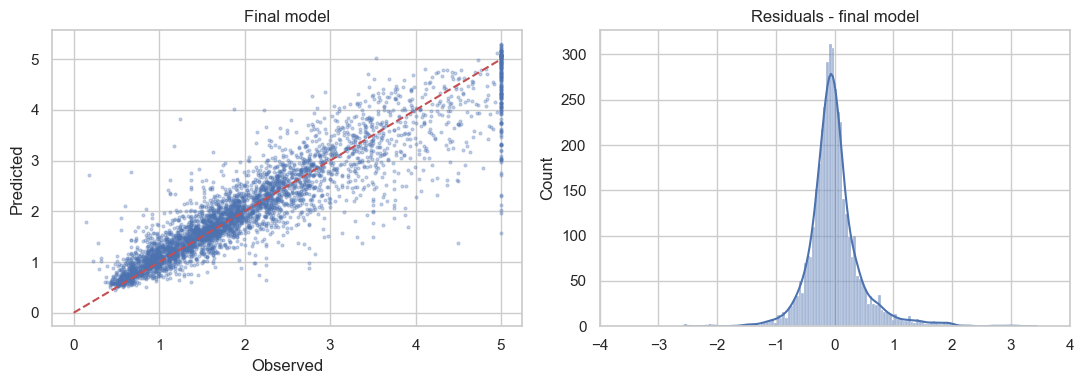

In [53]:
Hfig, axes = plt.subplots(1, 2, figsize=(11, 4))

#Predicted vs observed
axes[0].scatter(y_test_arr, pred_best, s=4, alpha=0.3)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_xlabel("Observed"); axes[0].set_ylabel("Predicted"); axes[0].set_title("Final model")

#Residuals histogram
sns.histplot(y_test_arr - pred_best, kde=True, ax=axes[1])
axes[1].set_title("Residuals - final model"); axes[1].set_xlim(-4, 4)

plt.tight_layout()
save_fig("final_model_diagnostics.png")
plt.show()

### 10.2 Where does the model fail?

Mean absolute error by price range. The censored group (>= $500,000) is expected to be the hardest: the true price is unknown beyond the cap.

,mean,count,mean ($)
Range,,,
<100k,0.198640,730,19864.0
100-200k,0.218090,1684,21809.0
200-300k,0.322607,956,32261.0
300-400k,0.481538,415,48154.0
400-500k,0.632173,159,63217.0
>=500k (capped),0.653352,184,65335.0


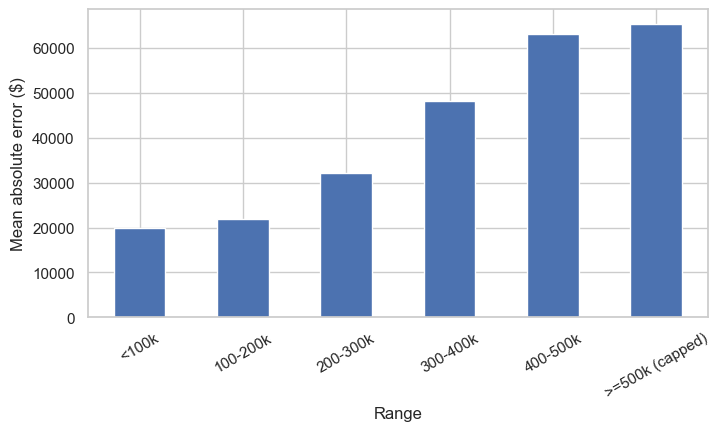

In [54]:
err = pd.DataFrame({"Price": y_test_arr, "AbsError": np.abs(y_test_arr - pred_best)})
err["Range"] = pd.cut(err["Price"], [0, 1, 2, 3, 4, CAP, 6],
                      labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k", ">=500k (capped)"],
                      right=False)
by_range = err.groupby("Range", observed=True)["AbsError"].agg(["mean", "count"])
by_range["mean ($)"] = (by_range["mean"] * 100_000).round(0)
display(by_range)

by_range["mean ($)"].plot(kind="bar", figsize=(8, 4), rot=30)
plt.ylabel("Mean absolute error ($)")
save_fig("error_by_price_range.png")
plt.show()

In [55]:
chk = pd.DataFrame({"Observed": y_test_arr, "Predicted": pred_best, "Range": err["Range"]})
print(chk.groupby("Range", observed=True)[["Observed", "Predicted"]].mean().mul(100_000).round(0))
print("Max prediction:", pred_best.max())

                 Observed  Predicted
Range                               
<100k             75748.0    92578.0
100-200k         151183.0   159933.0
200-300k         243994.0   243047.0
300-400k         344601.0   329645.0
400-500k         441186.0   387896.0
>=500k (capped)  500001.0   440094.0
Max prediction: 5.304851484428744


The mean absolute error increases steadily with the observed price, from about $\$20,000$ for districts below $\$100,000$ to about $\$65,000$ for capped districts. Districts above $\$300,000$ represent about 18% of the test set but concentrate about 34% of the total absolute error.

This pattern likely has several causes. High-priced districts are scarcer, prices are more variable at the high end, and models tend to regress towards the mean for extreme values. In addition, the recorded price of capped districts ($\$500,000$) is only a lower bound of the true value, so their actual error is probably larger than reported.

### 10.3 Feature importance

Permutation importance on the test set: how much the RMSE worsens when a feature is shuffled.

In [ ]:
perm = permutation_importance(best_model,
                              Xte_best,
                              y_test,
                              n_repeats=5,
                              random_state=SEED,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=Xte_best.columns).sort_values()

print(imp)
plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.xlabel("Increase in RMSE when shuffled")
plt.title("Permutation importance")
save_fig("feature_importance.png")
plt.show()

Permutation importance shows how much the test RMSE increases when each feature is shuffled. **Latitude** and **Longitude** are the most influential variables (RMSE increases of about 0.46 and 0.44), followed by **MedInc** (about 0.38).

Among the engineered features, **DistNearestCity** is the most relevant (about 0.17), while **RoomsPerPerson** and **BedroomRatio** contribute much less. Since **DistNearestCity** is derived from **Latitude** and **Longitude**, their importance is partly shared, and permutation importance reflects what the model relies on, not a causal effect on prices.

## 11. Conclusions

1. **What caused the poor baseline?**

The poor baseline performance was mainly caused by outliers in the features, where some variables showed implausible values, rather than by the censored target. This is supported by comparing four configurations of the linear regression: baseline (A), dropping the censored rows (B), clipping the outliers (C), and a combination of both (D). Experiment B reduced the RMSE by only 0.2%, whereas C reduced it by 8.9%, and D performed about the same as C. This suggests that the outliers affected the regression more than the censoring did. The coefficients point in the same direction: the coefficient of AveOccup goes from −0.0035 in the baseline to about −0.36 after clipping.

Even so, the best linear model leaves more than a third of the variance unexplained, and the non-linear models later achieved a much better fit, which suggests that the relationship between the features and the price is not purely linear.

2. **How much did better models help?**

It´s important to remark that the Linear models (Linear Regression and Ridge) didn´t fit the real data as well as the Decision Tree Ensamble models (Random Forest and Hist Gradient Boosting):
   * In cross-validation, the best linear configuration reached an RMSE of 0.6487 and an R² of 0.685, while Random Forest reduced the RMSE by about 24% (0.4910) and Hist Gradient Boosting by about 29% (0.4619, R² = 0.840).
  * On the test set, the selected model reached an RMSE of 0.4570 and an R² of 0.8406, compared to 0.7456 and 0.5758 for the baseline (a 38.7% reduction in RMSE).

The linear models assigns a single constant effect to each feature, which likely does not match this data set: the price depends on location and on interactions between variables in ways that a weighted sum cannot capture. They are also limited in interpretability: the variance inflation factors (section 7.2) show collinearity between Latitude and **Longitude** and between AveRooms and AveBedrms, so their individual coefficients cannot be read separately.

Among the tree-based models, Hist Gradient Boosting outperformed Random Forest by more than the fold-to-fold variability, so the difference is probably real. A plausible reason is that boosting builds trees sequentially, each one correcting the errors of the previous ones, while Random Forest averages independent trees. However, neither model was tuned, so this explanation remains a hypothesis.

3. **Did feature engineering help?**

Feature engineering improved all four models, although the gain was modest: cross-validated RMSE decreased by about 2.2% for Hist Gradient Boosting (0.4722 to 0.4619), 3.7% for Random Forest (0.5100 to 0.4910) and 3.0% for the linear models (0.6689 to 0.6487).

Based on the collinearity proven before between location variables (**Latitude** and **Longitude**) and the room distribution (**AveRooms** and **AveBedrms**), it´s logical to assume that building features from this relationships might be useful for training better the models.

The permutation importance suggests that **DistNearestCity** is the most useful engineered feature, while **RoomsPerPerson** and **BedroomRatio** contribute much less. Since the three features were added together, their individual effect on the RMSE cannot be isolated. Moreover, **DistNearestCity** is derived from **Latitude** and **Longitude**, so part of its importance is shared with them.

4. **Where does the final model fail?**

High-end districts are scarcer and exhibit greater price variance, causing models to regress toward the mean at the extremes. Furthermore, because the $\$500,000$ cap in censored districts acts only as a lower bound, the true prediction error in this segment is likely higher than reported.

5. **Practical meaning:**

An important result of this model comparison study is the reduction of the Mean Absolute Error (MAE). The baseline linear model, trained on the original dataset, had a typical prediction error of about $\$53,320$. By applying feature engineering and switching to the best-performing tree-based model (Hist Gradient Boosting), the average prediction error dropped by 43.6%, achieving a MAE of $\$30,069$. Given that the target mean in our original dataset is around $\$206,900$, this substantial reduction significantly improves overall predictive accuracy across most properties

## 12. Limitations and Future Improvements

- The target is capped at $\$500,000$, so predictions for expensive districts are unreliable by construction. Methods designed for censored targets (for example, Tobit-type models) could be explored.
- Data are aggregated at district level, so the model predicts a district's median value, not the price of an individual house.